# PDAN8412 Final Portfolio Of Evidence Nadira Ebrahim ST10534664

This final part of my Portfolio of Evidence will delve into the establishment of a convolution neural network that can be used for image recognition. This algorithm will be used to assist a book press company with enuring their premises remain safe and that only authorised personnel are allowed entry after undergoing facial recognition powered by the workings of this neural network. The dataset used contains images of various faces, and will categorise these people into different age categories. Although a facial recognition system does not classify ages, it works similarly by either allowing or not allowing individuals into a premises based on whether they are recognised by the algorithm. The dataset was obtained from Kaggle [at this link](https://www.kaggle.com/datasets/arashnic/faces-age-detection-dataset).

## Step 1: Import Libraries

Libraries optimise the commands required to carry out the mathematical operations, and various compuatational processes involved in creating a CNN algorithm that is capable of image recognition.

**Pandas:** This Python library was created by Wes McKinney in 2008 and it is crucial for cleaning datasets obtaining various statistical inferences from them, and essentially for exploring large datasets as a whole [1].

**NumPy:** Numerical Pythom (NumPy) library was created by Travis Oliphant in 2005. It is efficient at performing mathematical operations on arrays. An array works much faster than a list, which is why NumPy and its bililty to form arrays streamline various processes [2].

**TensorFlow:** TensorFlow is a machine learning framework created by Google in 2015. It acts as a symbolic math library, providing an adaptable graph-based architecture that brings flexibility, scalability, and distributed training to deeps learning. It is optimized for heavy computational tasks [3]. 

**OS:** The OS module in Python allows us to interact with the Operating System, in order to interact with the current directory, create a new one, delete files and directories, and create new ones [4].

**Matplotlib:** Matplotlib is used to produce graphs and plots that make it easier to view the dataset, locate outliers, and recognise trends [5].

**seaborn:** seaborn, built on Matplotlib is an advancement of Matplotlib. It created graphical representations that are specifically based on statistics from the dataset, and is especially useful for complex datasets [5].

**Scikit-learn:** Created by David Cournapeau in 2007, Scikit-learn (sklearn) allows for the development of machine learning algorithms with efficiency [6]. It contains various components that ease the scientific computing aspect of developing these algorithms [7]. 

In [1]:
# Import Pandas to read the data and create a dataframe from the dataset [1].
import pandas as pd
# Import NumPy for its mathematical operations [2].
import numpy as np
# Import TensorFlow to assist the model with processing sequential timesteps, updating weights, and managing cell states [3].
import tensorflow as tf
# Import OS to assist with file path management and directory creation [4].
import os
# Import Matplotlib to produce plots [5].
import matplotlib as mp
# Import the pyplot module of Matplotlib because this allows for customisation and simplifies the process of Exploratory Data Analysis [8].
import matplotlib.pyplot as plt
# Import seaborn to create more statistical representations of the data [5]
import seaborn as sns 
# Import Scikit-learn to assist with the evaluation of the model and its performance [6] [7].
from sklearn import metrics
from sklearn.metrics import confusion_matrix

## Step 2: Test Spark Environment

PySpark is critical for the building of large models that require lots of processing power, like the one I intend to build for this Assignment [9]. The dataset is also very big, so the model require additional power to manage the workload in order for the model to successfully be established. 

In [2]:
import os
import sys
import shutil
import pyspark
from pyspark.sql import SparkSession

# Configure Environment Variables 
# Point JAVA_HOME to the local JDK 8 installation and add its bin folder to PATH
os.environ["JAVA_HOME"] = r"C:/Users/lab_services_student/AppData/Local/Programs/Eclipse Adoptium/jdk-8.0.504.1-hotspot"
os.environ["PATH"] = os.environ["JAVA_HOME"] + r"/bin;" + os.environ["PATH"]

# Force Spark driver and workers to use the exact Python executable running this notebook
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# Verify Environment & Versions 
print("--- Environment Diagnostics ---")
print(f"Python Executable : {sys.executable}")
print(f"PySpark Version   : {pyspark.__version__}")
print(f"Java Executable   : {shutil.which('java')}")

variables = ['JAVA_HOME', 'HADOOP_HOME', 'SPARK_HOME', 'PYSPARK_PYTHON', 'PYSPARK_DRIVER_PYTHON', 'SPARK_LOCAL_IP']
for var in variables:
    print(f"{var:<22}: {os.getenv(var)}")

# Initialize Spark Session 
print("\n--- Starting SparkSession ---")
spark = SparkSession.builder \
    .appName("FaceAgeCNN") \
    .master("local[1]") \
    .config("spark.driver.host", "127.0.0.1") \
    .config("spark.driver.bindAddress", "127.0.0.1") \
    .getOrCreate()
test_data = [("Spark", "Working"), ("CNN", "Ready")]

# Run End-to-End Verification 
test_data = [("Spark", "Working"), ("CNN", "Ready")]
test_df = spark.createDataFrame(test_data, ["Component", "Status"])
test_df.show()

--- Environment Diagnostics ---
Python Executable : c:\tools\Anaconda3\envs\py311\python.exe
PySpark Version   : 3.5.8
Java Executable   : C:/Users/lab_services_student/AppData/Local/Programs/Eclipse Adoptium/jdk-8.0.504.1-hotspot/bin\java.EXE
JAVA_HOME             : C:/Users/lab_services_student/AppData/Local/Programs/Eclipse Adoptium/jdk-8.0.504.1-hotspot
HADOOP_HOME           : None
SPARK_HOME            : None
PYSPARK_PYTHON        : c:\tools\Anaconda3\envs\py311\python.exe
PYSPARK_DRIVER_PYTHON : c:\tools\Anaconda3\envs\py311\python.exe
SPARK_LOCAL_IP        : 127.0.0.1

--- Starting SparkSession ---
+---------+-------+
|Component| Status|
+---------+-------+
|    Spark|Working|
|      CNN|  Ready|
+---------+-------+



Spark is working and ready to be used! Great

## Step 3: Load the Data

In [3]:
# Read the dataset from a CSV file into a Pandas DataFrame.
df = pd.read_csv("train.csv")

In [4]:
# Display the first 10 rows of the DataFrame to get an overview of the dataset's structure and contents.
df.head(10)

,ID,Class
0,377.jpg,MIDDLE
1,17814.jpg,YOUNG
2,21283.jpg,MIDDLE
3,16496.jpg,YOUNG
4,4487.jpg,MIDDLE
5,6283.jpg,MIDDLE
6,23495.jpg,YOUNG
7,7100.jpg,YOUNG
8,6028.jpg,YOUNG
9,22617.jpg,OLD


The classes are categorical outputs, so we should convert this to numerical outputs so that it is easier to process. First let's see what all the possible outputs are.

In [5]:
# Let's check the unique values in the "Class" column.
df["Class"].unique()

<ArrowStringArray>
['MIDDLE', 'YOUNG', 'OLD']
Length: 3, dtype: str

In [6]:
# Now, let's replace the categorical values in the "Class" column with numerical values for easier processing in machine learning models. We will map 'YOUNG' to 0, 'MIDDLE' to 1, and 'OLD' to 2.  
df['Class'] = df['Class'].replace(['YOUNG', 'MIDDLE', 'OLD'], [0, 1, 2])

In [7]:
# Let's display the first few rows of the DataFrame again to confirm that the "Class" column has been updated correctly.
df.head()

,ID,Class
0,377.jpg,1
1,17814.jpg,0
2,21283.jpg,1
3,16496.jpg,0
4,4487.jpg,1


## Step 4: Preprocess the Data

In [8]:
# Let's see how many rows and columns are in the DataFrame.
df.shape

(19906, 2)

This is a massive dataset, containing 19 906 rows of records and 2 columns.

**Null Values**

Null values are missing values. These can cause errors when trying to work with the dataset. Often, they are removed. Let's check if the dataset has any missing values that need to be seen to [10].

In [9]:
# Let's check if the dataset contains any null values 
df.isnull().values.any()
# As a double check, let's do a sum of the null values 
df.isna().sum()

ID       0
Class    0
dtype: int64

Duplicated values will create bias when the model is training.

In [10]:
# Let's check if the dataset contains any duplicated values
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
19901    False
19902    False
19903    False
19904    False
19905    False
Length: 19906, dtype: bool

In [11]:
# Let's do some double checks
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19906 entries, 0 to 19905
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   ID      19906 non-null  str   
 1   Class   19906 non-null  object
dtypes: object(1), str(1)
memory usage: 477.9+ KB


This confirms that there are indeed no null values, and that every record has an age category assigned.

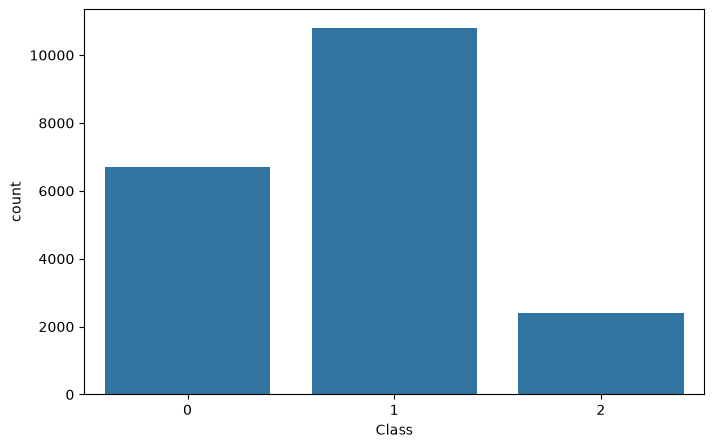

In [12]:
# Let's create a count plot to visualize the distribution of the "Class" variable in the dataset.
plt.figure(figsize=(8, 5))
order = ["0", "1", "2"]
ax = sns.countplot(data=df, x="Class", order=order)

Most of the images are those of individuals who are categorised as "middle" aged. The second most common age category is "young", and the age group that appears the least in this dataset are those categorised as "old".

In [13]:
# Let's create a function to read and preprocess the images. 
# This function takes the path to an image, the number of channels (default is 3 for RGB), and the desired resize dimensions (default is 150x150). 
def readImage(path,ch = 3, resize=(150,150)):
	di = tf.io.read_file(path)
	di = tf.image.decode_jpeg(di, channels=ch)
	di = tf.image.convert_image_dtype(di, dtype=tf.float32)
	di = tf.image.resize(di, resize)
	return di


In [14]:
# Let's create a function to load the image data and its corresponding label.
def load_data(image_path, label):
    img = readImage(image_path, 3, (150,150))
    return (img, label)

In [15]:
# Let's create a list to store the paths of all images in the "faces" directory and all of its subdirectories. 
PATH = "faces"
image_paths = []
for root, dirs, files in os.walk(PATH):
    for filename in files:
        image_paths.append(os.path.join(root, filename))
print(len(image_paths))

# Let's create a list to store the corresponding labels for each image.
response_list = []

for i in image_paths:
    _,tail = os.path.split(i)
    match = df.loc[df['ID'].astype(str) == str(tail), 'Class']
    response = match.iloc[0] if not match.empty else None
    response_list.append(response)

# Let's print the length of this list to verify that we have a label for each image.
print(len(response_list))

19906
19906


Because these numbers match, it is clear that every image has a label.

## Step 5: Train the Model

In [ ]:
# Let's split the dataset into training and testing sets. We will use 90% of the data for training and 10% for testing.
train_size = int(0.9 * len(image_paths))
test_size = len(image_paths) - train_size
print(train_size)
print(test_size)

17915
1991


In [17]:
# Let's preprocess the training dataset.
train_set = (train_set.map(load_data, num_parallel_calls=tf.data.AUTOTUNE).batch(64).prefetch(tf.data.AUTOTUNE))

In [18]:
# Let's preprocess the testing dataset.
test_set = (test_set.map(load_data, num_parallel_calls=tf.data.AUTOTUNE).batch(64).prefetch(tf.data.AUTOTUNE))

In [ ]:
# Let's build a Convolutional Neural Network (CNN) model using TensorFlow and Keras. 
# The model consists of convolutional layers, max pooling layers, a flattening layer, dense layers, and dropout for regularization. 
# The final layer uses softmax activation for multi-class classification.
from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Conv2D(filters=30, kernel_size=(3, 3), activation='relu', input_shape=(150, 150, 3), padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(3, activation='softmax')
])

c:\tools\Anaconda3\envs\py311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
# Let's compile the CNN model using the Adam optimizer, sparse categorical crossentropy loss function, and accuracy as the evaluation metric.
cnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [21]:
# Let's train the CNN model using the training dataset for 10 epochs and validate its performance using the testing dataset.
cnn_model.fit(train_set, epochs=10, validation_data=test_set)

Epoch 1/10


c:\tools\Anaconda3\envs\py311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


280/280 ━━━━━━━━━━━━━━━━━━━━ 166s 468ms/step - accuracy: 0.6046 - loss: 0.8604 - val_accuracy: 0.6655 - val_loss: 0.7503
Epoch 2/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 60s 215ms/step - accuracy: 0.6712 - loss: 0.7423 - val_accuracy: 0.6896 - val_loss: 0.7053
Epoch 3/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 56s 201ms/step - accuracy: 0.7005 - loss: 0.6872 - val_accuracy: 0.7062 - val_loss: 0.6818
Epoch 4/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 56s 201ms/step - accuracy: 0.7268 - loss: 0.6353 - val_accuracy: 0.7197 - val_loss: 0.6676
Epoch 5/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 56s 200ms/step - accuracy: 0.7532 - loss: 0.5852 - val_accuracy: 0.7102 - val_loss: 0.6655
Epoch 6/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 57s 202ms/step - accuracy: 0.7689 - loss: 0.5359 - val_accuracy: 0.7177 - val_loss: 0.6778
Epoch 7/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 56s 200ms/step - accuracy: 0.7934 - loss: 0.4875 - val_accuracy: 0.7097 - val_loss: 0.6921
Epoch 8/10
280/280 ━━━━━━━━━━━━━━━━━━━━ 63s 224ms/step - accuracy: 0.8078 - loss: 0.4499 - va

## Step 6: Evaluate the Model

In [22]:
# We can evaluate the model's performance on the training dataset to see how well it has learned from the data.
cnn_model.evaluate(train_set)

280/280 ━━━━━━━━━━━━━━━━━━━━ 20s 72ms/step - accuracy: 0.8735 - loss: 0.3166


[0.3166346251964569, 0.8735138177871704]

In [23]:
# We can also evaluate the model's performance on the testing dataset to see how well it generalizes to unseen data.
cnn_model.evaluate(test_set)

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - accuracy: 0.7288 - loss: 0.8013


[0.8013408184051514, 0.7287794947624207]

In [24]:
# Let's use the trained CNN model to make predictions on the testing dataset. 
# The model will output the predicted class probabilities for each image in the test set.
test_pred = cnn_model.predict(test_set)

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step


In [25]:
# Let's convert the predicted probabilities into class labels by taking the index of the maximum value for each prediction.
y_labels = [np.argmax(item) for item in test_pred]
print("Test Predictions response sample:",y_labels[:10])
# Let's create a list to store the true labels for the test set.
test_response = response_list[train_size:]
print("Test True response sample:", test_response[:10])

Test Predictions response sample: [np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(2)]
Test True response sample: [1, 0, 1, 1, 0, 1, 2, 0, 0, 2]


In [30]:
# Let's create a confusion matrix to evaluate the performance of the CNN model on the testing dataset.
class_names = ['YOUNG','MIDDLE','OLD']
def plot_confusion_matrix(y_true, y_pred, classes,
                          normalize=False,
                          title=None,
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if not title:
        if normalize:
            title = 'Normalized confusion matrix'
        else:
            title = 'Confusion matrix, without normalization'

    # Compute confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

        print(cm)

    fig, ax = plt.subplots(figsize=(7,7))
    im = ax.imshow(cm, interpolation='nearest', cmap=cmap)
    ax.figure.colorbar(im, ax=ax)
    # We want to show all ticks...
    ax.set(xticks=np.arange(cm.shape[1]),
           yticks=np.arange(cm.shape[0]),
           # ... and label them with the respective list entries
           xticklabels=classes, yticklabels=classes,
           title=title,
           ylabel='True label',
           xlabel='Predicted label')

    # Rotate the tick labels and set their alignment.
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right",
             rotation_mode="anchor")
    # Loop over data dimensions and create text annotations.
    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], fmt),
                    ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black")
    fig.tight_layout()
    return ax


np.set_printoptions(precision=2)

Confusion matrix, without normalization
[[425 193  17]
 [122 923  55]
 [ 40 113 103]]


<Axes: title={'center': 'Confusion matrix, without normalization'}, xlabel='Predicted label', ylabel='True label'>

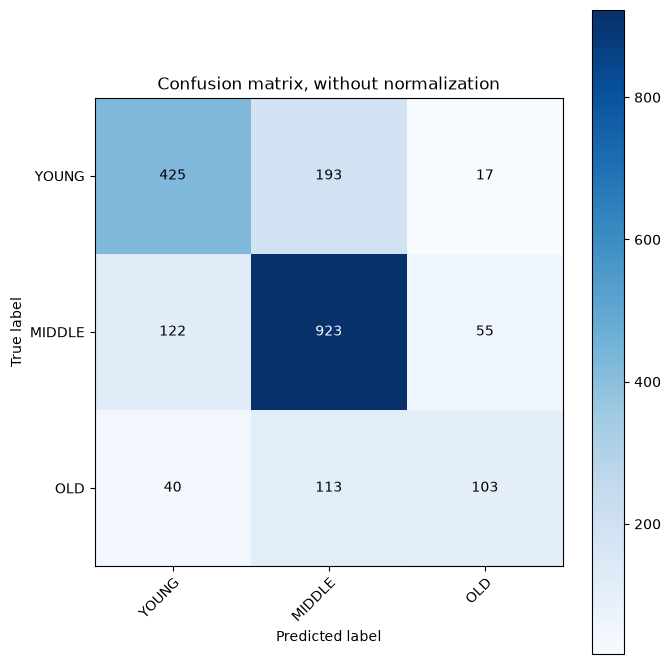

In [31]:
plot_confusion_matrix(test_response, y_labels, classes=class_names,
                      title='Confusion matrix, without normalization')

Normalized confusion matrix


<Axes: title={'center': 'Normalized confusion matrix'}, xlabel='Predicted label', ylabel='True label'>

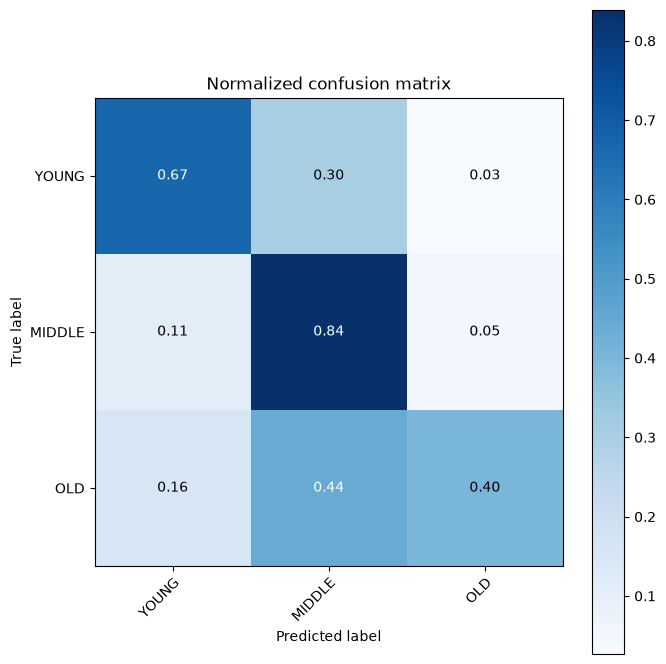

In [32]:
# Plot the normalized confusion matrix
plot_confusion_matrix(test_response, y_labels, classes=class_names, normalize=True,
                      title='Normalized confusion matrix')

# References

[1] “Pandas Introduction.” [Online]. Available: https://www.w3schools.com/python/pandas/pandas_intro.asp

[2] “Introduction to NumPy.” Accessed: Apr. 10, 2026. [Online]. Available: https://www.w3schools.com/python/numpy/numpy_intro.asp

[3] “TensorFlow vs. Keras: What’s the Difference? | Coursera.” Accessed: Sep. 21, 2026. [Online]. Available: https://www.coursera.org/articles/tensor-flow-vs-keras

[4] “OS Module in Python with Examples - GeeksforGeeks.” Accessed: Nov. 18, 2026. [Online]. Available: https://www.geeksforgeeks.org/python/os-module-python-examples/

[5] “Matplotlib — Visualization with Python.” Accessed: Apr. 10, 2026. [Online]. Available: https://matplotlib.org/ 

[6] F. Pedregosa FABIANPEDREGOSA et al., “Scikit-learn: Machine Learning in Python,” Journal of Machine Learning Research, vol. 12, no. 85, pp. 2825–2830, 2011, Accessed: Apr. 11, 2026. [Online]. Available: http://jmlr.org/papers/v12/pedregosa11a.html

[7] “What is Scikit-Learn (Sklearn)? | IBM.” Accessed: Apr. 10, 2026. [Online]. Available: https://www.ibm.com/think/topics/scikit-learn

[8] “Matplotlib Pyplot - GeeksforGeeks.” Accessed: Apr. 13, 2026. [Online]. Available: https://www.geeksforgeeks.org/python/pyplot-in-matplotlib/

[9] “PySpark Tutorial - GeeksforGeeks.” Accessed: Sep. 21, 2026. [Online]. Available: https://www.geeksforgeeks.org/python/pyspark-tutorial/

[10] “Difference between Null, Empty and Missing Data - The Data School.” Accessed: Apr. 13, 2026. [Online]. Available: https://www.thedataschool.co.uk/shahbaz-khan/difference-between-null-and-missing-data/  